# Lesson 3: Visualization (Matplotlib + Seaborn)

**EDA ka asal matlab: data se sawal poochna.** Har chart ek sawal ka jawab hai. Pehle sawal, phir chart.

| Sawal | Chart |
|---|---|
| Waqt ke saath kya badla? | Line (`plt.plot`) |
| Do numbers ka rishta? | Scatter (`plt.scatter`) |
| Categories compare karni hain? | Bar (`plt.bar`, `sns.barplot`, `sns.countplot`) |
| Data kahan jama hai? | Histogram (`plt.hist`) |
| Typical score, consistency, outliers? | Box plot (`sns.boxplot`) |
| Saare numeric rishte ek nazar mein? | Heatmap (`sns.heatmap`) |

In [1]:
# Saare imports sab se upar, ek hi dafa
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## Part 1: Matplotlib kya hai?

School ke graph paper jaisa: neeche **x-axis**, side pe **y-axis**, points lagao, phir jor do.
Matplotlib yahi kaam code se karta hai: aap **x values** aur **y values** dete hain.

**Data:** T20 innings ke pehle 5 overs ke baad total score.
```
Over:          1    2    3    4    5
Total score:   6   14   20   31   40
```

### Step 1: Sab se chhota chart

| Line | Kaam |
|---|---|
| `overs = [...]` | x-axis ki values |
| `score = [...]` | y-axis ki values |
| `plt.plot(overs, score)` | points (1,6), (2,14)... lagao aur **lakeer se jor do** |
| `plt.show()` | chart **dikhao** |

Dono lists ki **length barabar** honi chahiye (NumPy wala "aligned" rule).

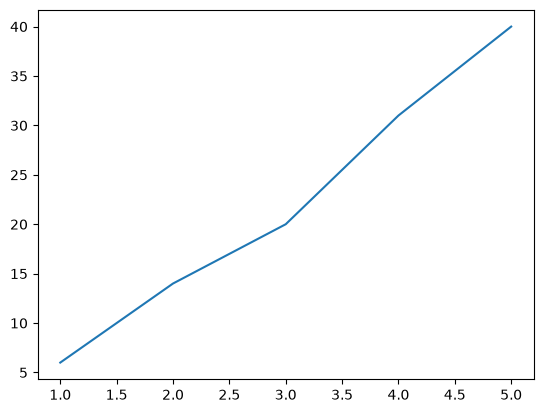

In [2]:
overs = [1, 2, 3, 4, 5]
score = [6, 14, 20, 31, 40]

plt.plot(overs, score)
plt.show()

### Step 2: Chart ko samajhne layak banana

| Nayi cheez | Kya badla |
|---|---|
| `marker="o"` | har point pe **dot**, taake asal values nazar aayein |
| `plt.title(...)` | upar **heading** |
| `plt.xlabel(...)` / `plt.ylabel(...)` | dono lines ke **naam** |

Step 1 wale chart se pata nahi chalta tha ke ye kis cheez ka chart hai. Ab foran pata chalta hai.
**Rule:** `plt.show()` hamesha **aakhir mein**. Uske upar jo likho, chart mein jurta jata hai.

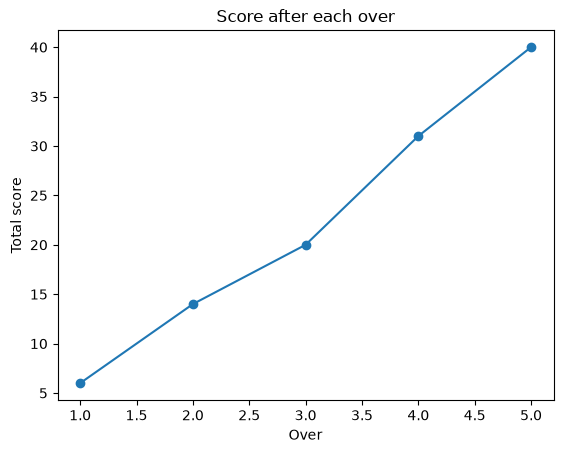

In [3]:
plt.plot(overs, score, marker="o")
plt.title("Score after each over")
plt.xlabel("Over")
plt.ylabel("Total score")
plt.show()

### Step 3: Same data, sirf dots (scatter)
Sirf ek lafz badla: `plot` → `scatter`.

| | `plt.plot` | `plt.scatter` |
|---|---|---|
| Kya banata hai | dots **jor ke lakeer** | sirf **dots** |
| Kab | cheez **waqt ke saath** badle | do cheezon ka **rishta** dekhna ho, points ka koi order na ho |

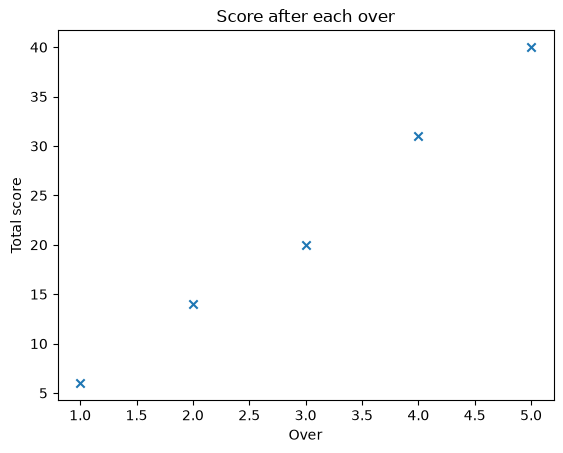

In [4]:
plt.scatter(overs, score, marker="x")
plt.title("Score after each over")
plt.xlabel("Over")
plt.ylabel("Total score")
plt.show()

### Step 4: Bar chart
Har over mein **kitne runs** bane (total nahi). Har over ka ek **khamba**: jitne zyada runs, utna lamba.
**Bar kab:** jab **alag alag cheezon** ko compare karna ho. Jawab dhoondne ka tareeqa: **sab se lamba khamba** dekho.

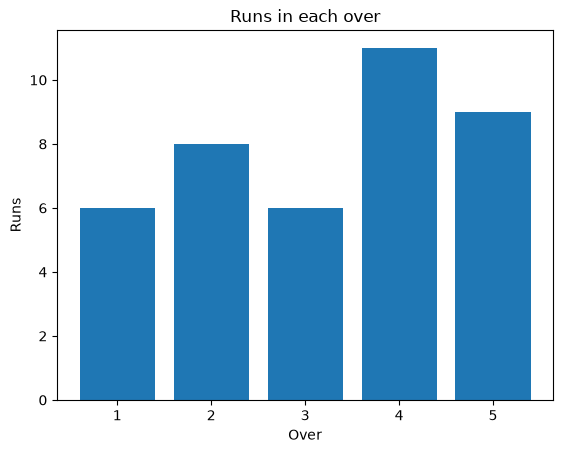

In [5]:
runs_in_over = [6, 8, 6, 11, 9]

plt.bar(overs, runs_in_over)
plt.title("Runs in each over")
plt.xlabel("Over")
plt.ylabel("Runs")
plt.show()

### Natija
- Sab se lamba khamba **4th over** (11 runs)
- Har chart ka **ek hi dhancha** hai, sirf pehli line badalti hai:
```
plt.<plot / scatter / bar>(x, y)
plt.title(...)
plt.xlabel(...)
plt.ylabel(...)
plt.show()
```
- Babar ki pichli 5 innings dikhani hon: **bar** = har innings compare karni ho · **plot** = form ka trend dekhna ho. Jo sawal poochna hai, chart wahi chunein.

---
## Part 2: Histogram, aahista

Sawal: **"Ye batsman zyada tar kitne runs banata hai?"**
12 alag numbers dekh ke jawab mushkil hai. To inhein **dabbon (ranges)** mein daalte hain, tally marks ki tarah.

```
45, 67, 12, 89, 34, 23, 0, 51, 102, 20, 31, 55
```

### Step 1: Haath se ginti

| Dabba | Kaun si innings | Ginti |
|---|---|---|
| 0–19 | 12, 0 | **2** |
| 20–39 | 34, 23, 20, 31 | **4** |
| 40–59 | 45, 51, 55 | **3** |
| 60–79 | 67 | **1** |
| 80–99 | 89 | **1** |
| 100–119 | 102 | **1** |

Total = 12 ✅

### Step 2: Is ginti ka bar chart (ginti humne khud ki)

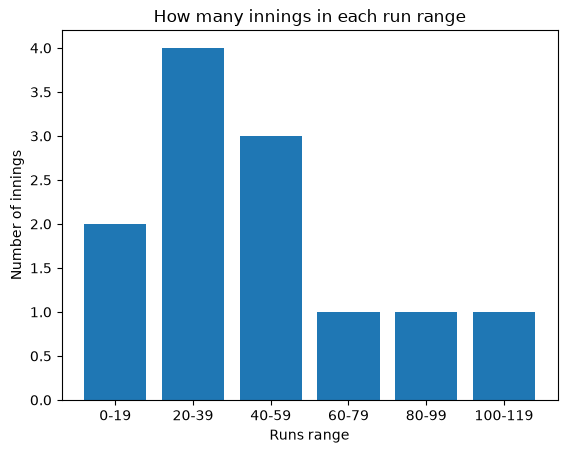

In [6]:
ranges = ["0-19", "20-39", "40-59", "60-79", "80-99", "100-119"]
counts = [2, 4, 3, 1, 1, 1]

plt.bar(ranges, counts)
plt.title("How many innings in each run range")
plt.xlabel("Runs range")
plt.ylabel("Number of innings")
plt.show()

### Step 3: Yahi kaam `plt.hist` khud karta hai
Ab ginti nahi karni. **Kachha data** do, aur dabbon ki hadein (`bins`) batao.

| | `plt.bar` | `plt.hist` |
|---|---|---|
| Aap kya dete ho | **ginti khud** karke | **kachha data** (12 scores) |
| Ginti kaun karta hai | aap | Matplotlib |

- `bins=[0, 20, 40, ...]` = dabbon ki hadein
- `edgecolor="black"` = khambon ke beech lakeer

**Histogram = "ginti karke bar chart", automatic.** Shakal Step 2 jaisi hi honi chahiye (2, 4, 3, 1, 1, 1).

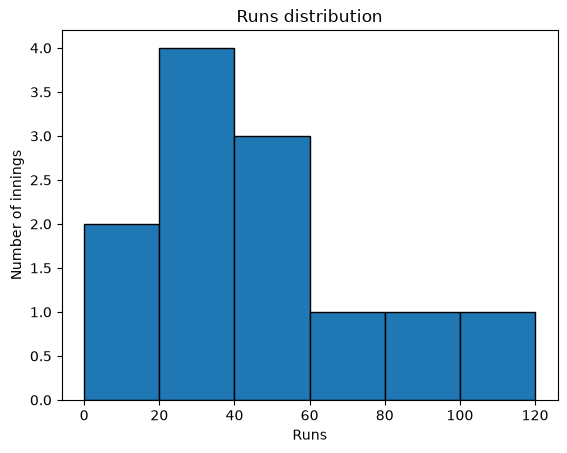

In [7]:
runs = [45, 67, 12, 89, 34, 23, 0, 51, 102, 20, 31, 55]

plt.hist(runs, bins=[0, 20, 40, 60, 80, 100, 120], edgecolor="black")
plt.title("Runs distribution")
plt.xlabel("Runs")
plt.ylabel("Number of innings")
plt.show()

### Natija
Sab se lamba khamba **20–39**: batsman zyada tar 20 se 39 ke beech banata hai.
Zyada tar scores **chhote** (0–59), kuch hi **bare** (60+). Cricket mein ye aam pattern hai, aur model banate waqt **target ka phailao** jaanna zaroori hai.

---
## Part 3: Lists ki jagah Pandas ka data

`df["runs"]` bhi list jaisa hi hai, numbers ki ek line. **Jahan list likhi thi, wahan column likh do. Chart ka code wahi.**
```
plt.hist(runs, ...)          ← list
plt.hist(df["runs"], ...)    ← DataFrame ka column
```

In [8]:
df = pd.read_csv("../data/innings_clean.csv")
df.head()

,match_date,player,opposition,venue,batting_position,balls,runs
0,2024-01-10,Babar,India,Karachi,3,30.0,45.0
1,2024-01-10,Rizwan,India,Karachi,1,50.0,67.0
2,2024-01-15,Fakhar,Australia,Lahore,2,60.0,89.0
3,2024-01-15,Babar,Australia,Lahore,3,15.0,12.0
4,2024-01-20,Rizwan,England,Dubai,1,28.0,34.0


### Histogram, column se
Ye bilkul Part 2 wala chart hai, kyunki `innings_clean.csv` mein yahi 12 scores hain.

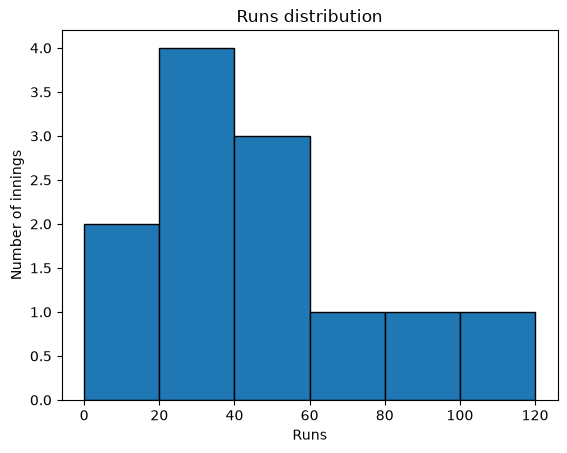

In [9]:
plt.hist(df["runs"], bins=[0, 20, 40, 60, 80, 100, 120], edgecolor="black")
plt.title("Runs distribution")
plt.xlabel("Runs")
plt.ylabel("Number of innings")
plt.show()

### Scatter, do columns se
CSV ki **har row ek dot**: x = us row ki balls, y = us row ke runs.

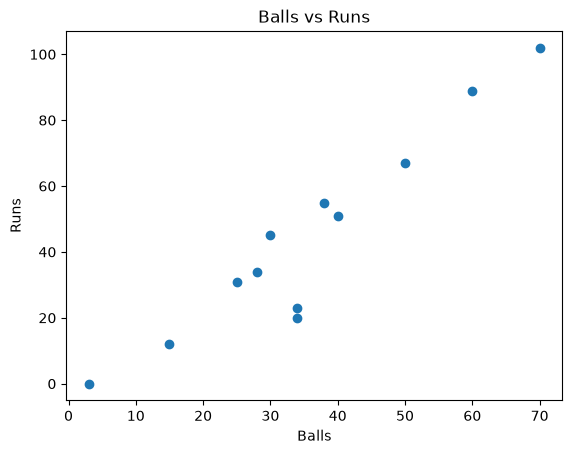

In [10]:
plt.scatter(df["balls"], df["runs"])
plt.title("Balls vs Runs")
plt.xlabel("Balls")
plt.ylabel("Runs")
plt.show()

### Natija: is chart mein ek chhupi kahani hai 🔍
1. **Relationship:** dots neeche-left se upar-right, seedhi lakeer jaise → **zyada balls = zyada runs** (linear rishta).
2. **x = 34 pe do dots** (20 aur 23 runs), ek ke upar ek, aur lakeer se **neeche**. Ye wahi 2 rows hain jinki balls hum ne **median (34) se bhari** thin (Fakhar ki khali value aur Babar ki −12).

**Imputation data ko badal deta hai.** Bhari hui values ek jagah **jama** ho jati hain aur asal pattern bigaar sakti hain. `describe()` ye nahi batata, **chart ek nazar mein** dikha deta hai.
(Professional tip: `balls_was_missing` jaisa True/False column bana lein, taake model ko pata ho kaunsi value asli hai.)

### Bar chart: pehle table banao (do qadam)
CSV mein har player ki **kai rows** hain, humein har player ka **ek number** chahiye. Isliye pehle `groupby`.

- `player_runs.index` = khambon ke **naam** (x)
- `player_runs.values` = khambon ki **lambai** (y)

In [11]:
# Qadam A: table
player_runs = df.groupby("player")["runs"].sum()
player_runs

player
Babar     132.0
Fakhar    245.0
Rizwan    152.0
Name: runs, dtype: float64

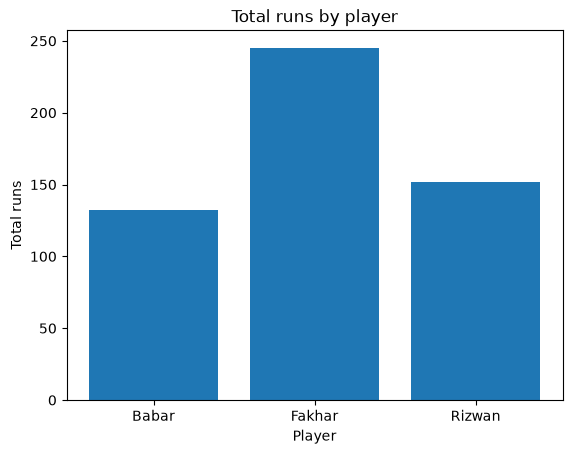

In [12]:
# Qadam B: chart
plt.bar(player_runs.index, player_runs.values)
plt.title("Total runs by player")
plt.xlabel("Player")
plt.ylabel("Total runs")
plt.show()

### Do common ghaltiyan (bar chart)
```python
plt.bar(df["runs"], df["opposition"])   # ❌
```
1. **groupby bhool gaye:** 12 rows → 12 patle khambe, har innings ka ek
2. **x aur y ulte:** `plt.bar(x, y)` mein **x = naam (category)**, **y = lambai (number)**

Sahi tareeqa, opposition ke liye:

opposition
Australia    121.0
England      159.0
India        249.0
Name: runs, dtype: float64


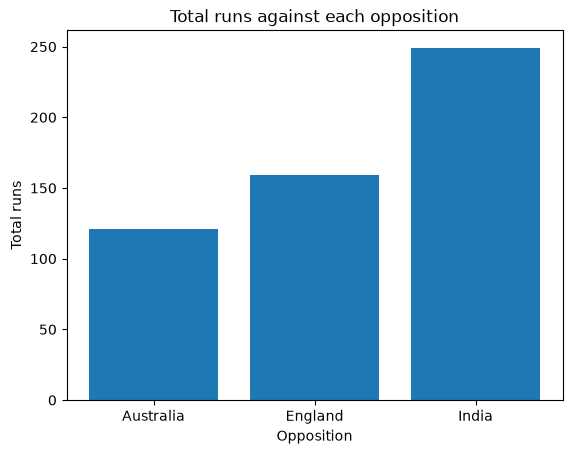

In [13]:
opp_runs = df.groupby("opposition")["runs"].sum()
print(opp_runs)   # beech mein table dekhna ho to print, warna sirf aakhri line dikhti hai

plt.bar(opp_runs.index, opp_runs.values)
plt.title("Total runs against each opposition")
plt.xlabel("Opposition")
plt.ylabel("Total runs")
plt.show()

### Line chart: ek player ki form (filter → sort → plot)
`sort_values("match_date")` **zaroori** hai, warna lakeer waqt ke order mein nahi chalegi.
Variable ka naam wahi rakhein jo andar hai (`fakhar`, `rizwan`), warna baad mein confusion hoti hai.

In [14]:
fakhar = df[df["player"] == "Fakhar"].sort_values("match_date")
fakhar[["match_date", "runs"]]

,match_date,runs
2,2024-01-15,89.0
5,2024-01-20,23.0
8,2024-02-08,102.0
10,2024-02-20,31.0


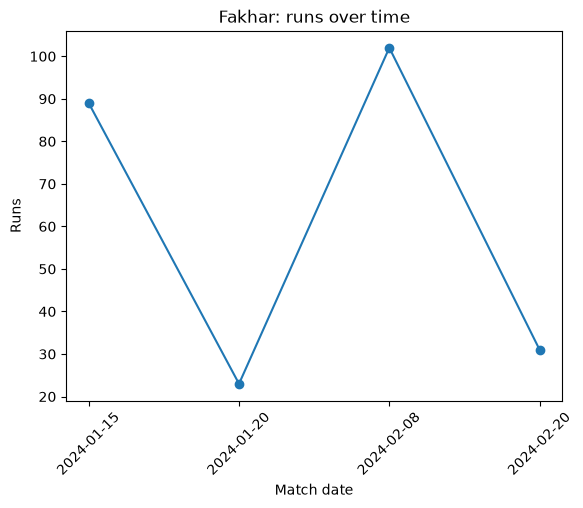

In [15]:
plt.plot(fakhar["match_date"], fakhar["runs"], marker="o")
plt.title("Fakhar: runs over time")
plt.xlabel("Match date")
plt.ylabel("Runs")
plt.xticks(rotation=45)   # dates tirchi, taake ek doosre pe na charhein
plt.show()

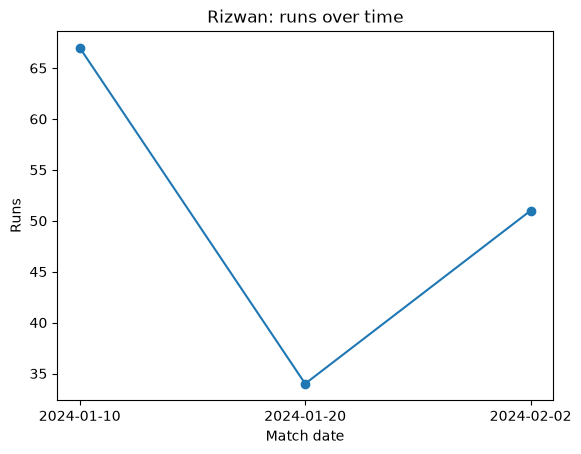

In [16]:
rizwan = df[df["player"] == "Rizwan"].sort_values("match_date")

plt.plot(rizwan["match_date"], rizwan["runs"], marker="o")
plt.title("Rizwan: runs over time")
plt.xlabel("Match date")
plt.ylabel("Runs")
plt.show()

### Khulasa (Part 3)
```
Seedha column:        hist, scatter    →  df["col"] seedha do
Pehle table banao:    bar              →  groupby → index & values
Pehle filter + sort:  line (form)      →  filter → sort_values → plot
```
Rizwan: 67 → 34 → 51 (pehle achha, phir gira, phir wapas upar).

---
## Part 4: Seaborn — groupby khud karta hai

Matplotlib mein bar chart **do qadam** mein bana. **Seaborn ye dono ek line mein** karta hai: aap table aur **column ke naam** dete hain, groupby woh andar khud karta hai.
Seaborn, Matplotlib ke **upar** bana hai, isliye `plt.title()`, `plt.show()` wahi rehte hain.

| Parameter | Matlab |
|---|---|
| `data=df` | kaun sa table |
| `x="opposition"` | khambon ke **naam** kis column se |
| `y="runs"` | khambon ki **lambai** kis column se |
| `estimator="sum"` | har group ka **jor** (default **average** hai) |
| `errorbar=None` | extra lakeer band |

Column ka naam **string** mein (`"runs"`), `df["runs"]` nahi.

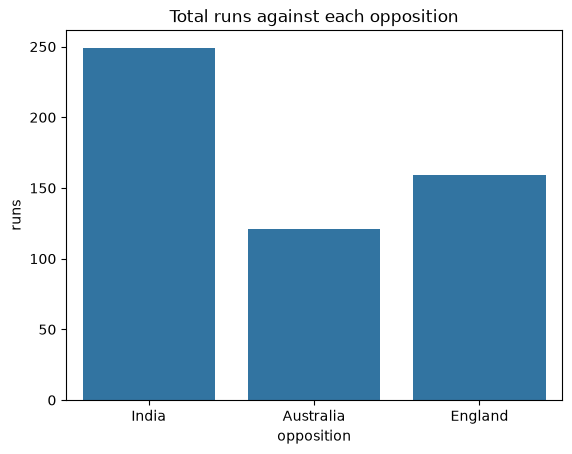

In [17]:
# Wahi chart jo Matplotlib se bana tha (249, 159, 121)
sns.barplot(data=df, x="opposition", y="runs", estimator="sum", errorbar=None)
plt.title("Total runs against each opposition")
plt.show()

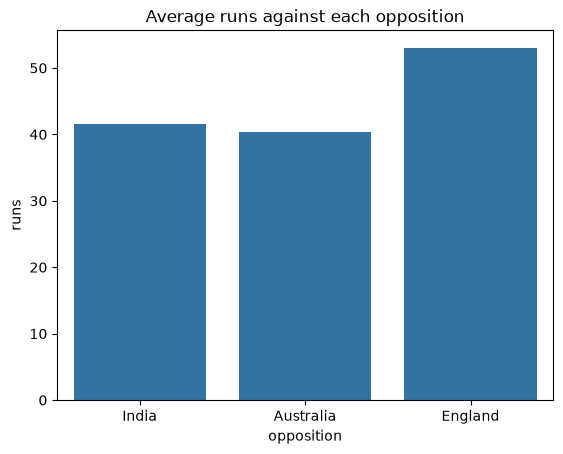

In [18]:
# estimator hata diya → default average
sns.barplot(data=df, x="opposition", y="runs", errorbar=None)
plt.title("Average runs against each opposition")
plt.show()

### countplot: kitni innings?
Sirf **ginti** karta hai (har team ke khilaf kitni rows). `y` ki zaroorat nahi. Ye `value_counts()` ka chart hai.

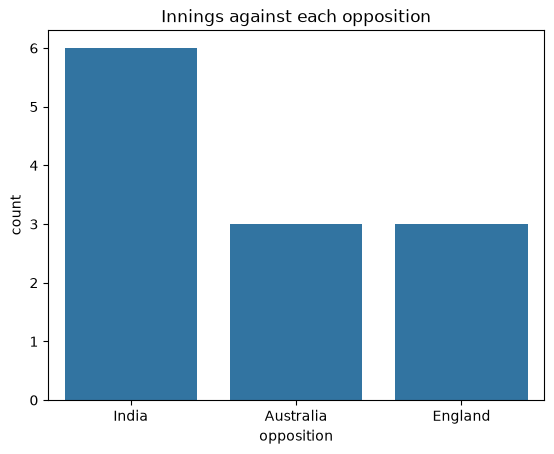

In [19]:
sns.countplot(data=df, x="opposition")
plt.title("Innings against each opposition")
plt.show()

### Natija
- **Total** mein India sab se upar (249), lekin **average** mein **England** (~53)
- Wajah: India ke khilaf **6 innings**, baaki dono ke khilaf sirf 3. Zyada innings = zyada total.

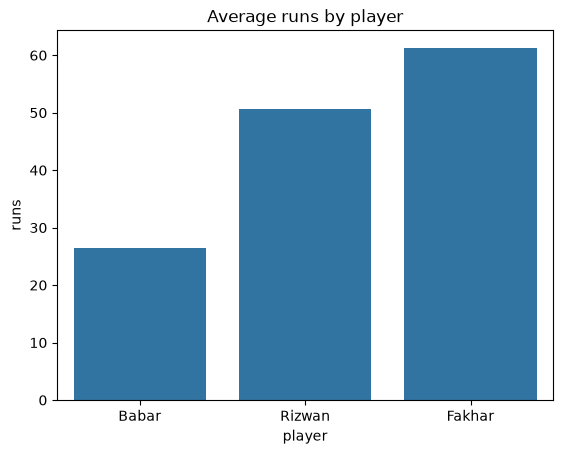

In [20]:
sns.barplot(data=df, x="player", y="runs", errorbar=None)
plt.title("Average runs by player")
plt.show()

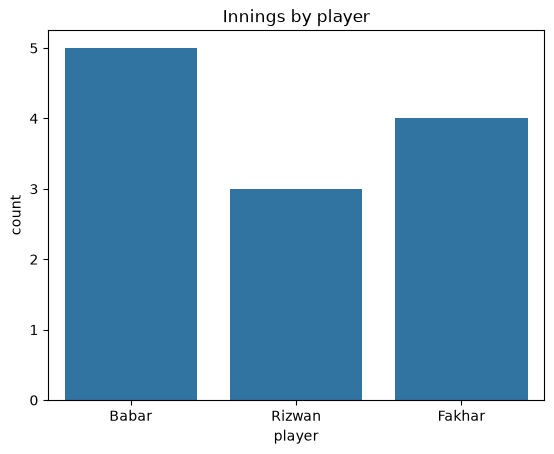

In [21]:
sns.countplot(data=df, x="player")
plt.title("Innings by player")
plt.show()

### Natija
Fakhar ka average sab se zyada (~61) aur max bhi (102). Lekin 3–5 innings **bohat kam** hain; cricket mein pakka faisla 30–40 innings ke baad hota hai.

```
Total    →  dhoka de sakta hai (jis ke matches zyada, wo upar)
Average  →  behtar comparison
Count    →  hamesha saath dekho: average KITNE data se bana?
```

---
## Part 5: Box plot — `describe()` ki tasveer

Ek tasveer mein 5 numbers: min, Q1 (25%), median (50%), Q3 (75%), max.

```
   ┬   ← upar wali lakeer ka sira (max, outlier na ho to)
 ┌─┴─┐ ← Q3 (75%)
 │───│ ← MEDIAN (50%)
 └─┬─┘ ← Q1 (25%)
   ┴   ← neeche wali lakeer ka sira (min)
   ●   ← box se door akela dot = OUTLIER
```

### Step 1: Saare runs ka ek box, numbers ke saath

In [22]:
df["runs"].describe()

count     12.000000
mean      44.083333
std       30.651882
min        0.000000
25%       22.250000
50%       39.500000
75%       58.000000
max      102.000000
Name: runs, dtype: float64

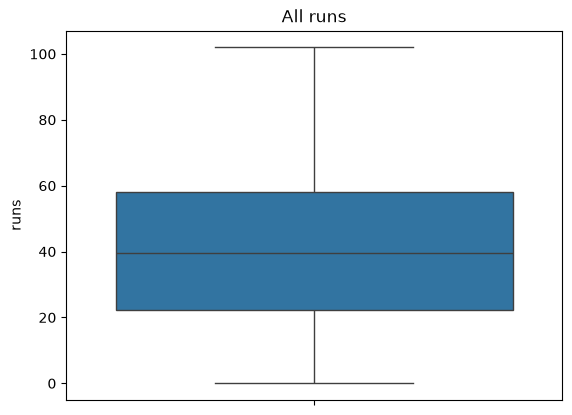

In [23]:
sns.boxplot(data=df, y="runs")
plt.title("All runs")
plt.show()

Sorted: `0 12 20 23 31 34 45 51 55 67 89 102`
- Q1 ≈ **22.25**, median = (34+45)/2 = **39.5**, Q3 = **58**
- Box ke andar = beech wali **aadhi** innings

### Step 2: Outlier kaisa dikhta hai? (purana 610 typo wapas)

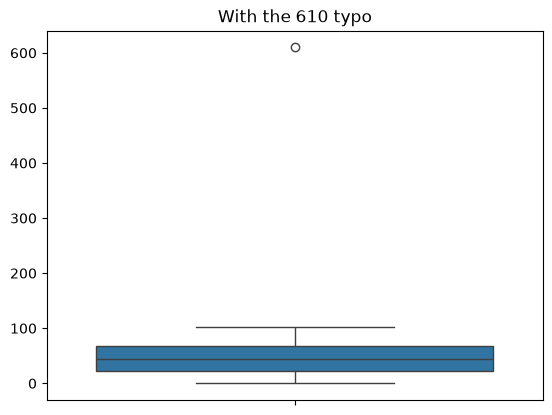

In [24]:
sns.boxplot(y=[0, 12, 20, 23, 31, 34, 45, 51, 55, 67, 89, 102, 610])
plt.title("With the 610 typo")
plt.show()

Upar **akela dot** = outlier. Aur dekhein: ek ghalat value ki wajah se baaki saara data neeche **patli pati** ban gaya. **Ek outlier poore chart (aur model) ko bigaar deta hai.**

⚠️ **Outlier ≠ ghalti.** 102 bara hai lekin cricket mein mumkin (asli). 610 na-mumkin (ghalti). Formula sirf **shak** paida karta hai, faisla **domain knowledge** karta hai.

### Step 3: Har player ka box

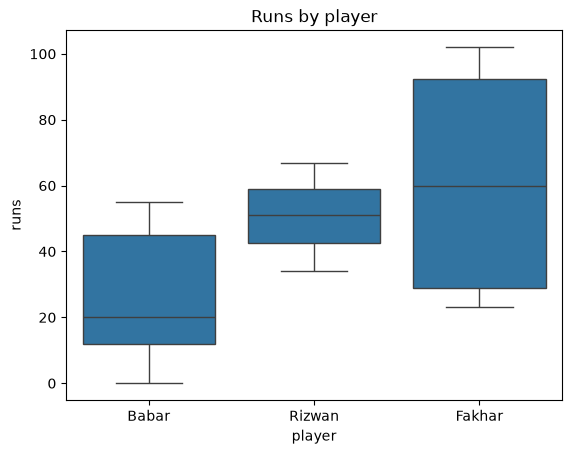

In [25]:
sns.boxplot(data=df, x="player", y="runs")
plt.title("Runs by player")
plt.show()

### Box plot kaise padhein

| Kya dekhna hai | Kya batata hai |
|---|---|
| Andar ki lakeer **kitni upar** (position) | **kitne runs** (typical score) |
| Box **kitna lamba** (size) | **kitna bharosemand** (consistency) |

⚠️ "Chhota box" ka matlab **neeche hona nahi**, balke **patla** hona.

| Player | Box (taqreeban) | Matlab |
|---|---|---|
| **Fakhar** | 29 → 92 (sab se lamba), median ~60 | sab se zyada runs, lekin **inconsistent**: ya bara score ya jaldi out |
| **Rizwan** | 43 → 59 (sab se chhota) | **consistent** anchor (lekin sirf 3 innings) |
| **Babar** | 12 → 45, median 20 | is data mein **form kamzor** |

> **Lakeer kahan hai = kitne runs. Box kitna lamba hai = kitna bharosemand.**

ML connection: consistent player ke runs predict karna **aasaan**, inconsistent ka **mushkil**. Kuch players ka score fitrat se hi unpredictable hota hai.

---
## Part 6: Correlation heatmap

Correlation = do columns ka **linear rishta**, ek number mein, **−1 se +1**:
```
 -1 ────────────── 0 ────────────── +1
 ek barhe,         koi seedha       ek barhe,
 doosra ghate      rishta nahi      doosra bhi barhe
```
| Number | Matlab |
|---|---|
| 0.7 – 1.0 | mazboot |
| 0.3 – 0.7 | darmiyana |
| 0 – 0.3 | kamzor / nahi |

### Step 1: Ek jora

In [26]:
df["balls"].corr(df["runs"])

np.float64(0.9462700463943546)

### Step 2: Saare numeric columns (table)
- `numeric_only=True` → sirf numbers (player, opposition text hain)
- Diagonal pe **1.0** (har column ka khud se rishta)
- Table dono taraf **same** (balls vs runs = runs vs balls)

In [27]:
corr = df.corr(numeric_only=True)
corr

,batting_position,balls,runs
batting_position,1.000000,-0.410397,-0.38427
balls,-0.410397,1.000000,0.94627
runs,-0.384270,0.946270,1.00000


### Step 3: Rangon mein (heatmap)
| Parameter | Kaam |
|---|---|
| `annot=True` | har dabbe mein number |
| `cmap="coolwarm"` | **laal** = positive, **neela** = negative |
| `vmin=-1, vmax=1` | rang ka scale fix |

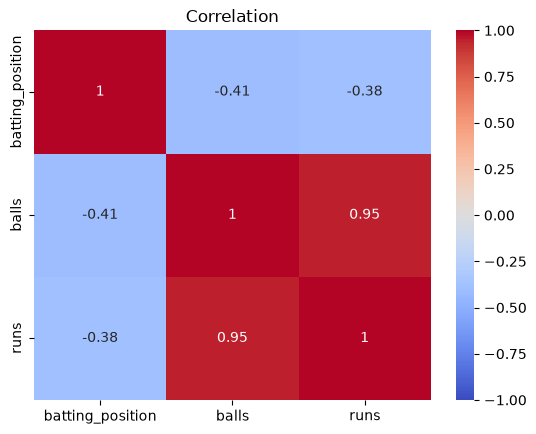

In [28]:
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation")
plt.show()

### Natija: teen sabaq

**1. balls vs runs ≈ 0.95 → 🚨 leakage alarm**
Bohat mazboot, lekin `balls` innings **ke baad** pata chalta hai. Innings se pehle prediction ke liye ye feature istemal nahi ho sakta.
> Jab koi feature target se "bohat achha" jura ho, khush hone se pehle poochein: **ye value KAB pata chalti hai?**

**2. batting_position vs runs ≈ −0.38 → bharosa nahi**
- `batting_position` asal mein **category** hai, number nahi
- Har position pe **sirf ek player** hai (1 = Rizwan, 2 = Fakhar, 3 = Babar). To ye number "position ka asar" nahi, balke **Babar ki kharab form** naap raha hai.

**3. Correlation ≠ causation**
Do cheezein saath upar neeche hon to zaroori nahi ek doosri ki **wajah** ho. Aksar teesri cheez (yahan **player**) peeche chhupi hoti hai.

---
## Khulasa
- **Pehle sawal, phir chart**
- Har chart ka dhancha same: `plt.<chart>(...)` → title → labels → `show()`
- Matplotlib: groupby **aap** karo · Seaborn: groupby **khud**
- Total ke saath **count** hamesha dekho
- Chart pe **shak** karo: imputed values (34 balls wale dots), leakage (0.95), chhupi wajah (−0.38)